# Part 0: Cleaning the raw Kanpur sensor data

**Input:** `kanpur_pm25_raw_jul_aug_2026.csv`, from 76 low-cost PM2.5 sensors, 1 Jul to 31 Aug 2026,
one row every 15 minutes (UTC). Each sensor has three columns: `<id>_latitude`, `<id>_longitude`,
`<id>_pm25`.

**Output:** `outputs/kanpur_hourly_clean.csv`, an hourly long table with a `flag` column.
We never delete or fill readings. Problems are only *flagged*.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../mp1-package/data")      # folder with the course data files
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

raw = pd.read_csv(DATA / "kanpur_pm25_raw_jul_aug_2026.csv", parse_dates=["timestamp_utc"])
sensor_ids = [c.replace("_pm25", "") for c in raw.columns if c.endswith("_pm25")]
print("rows:", len(raw), "| sensors:", len(sensor_ids))
print("time range:", raw.timestamp_utc.min(), "to", raw.timestamp_utc.max())

rows: 5952 | sensors: 76
time range: 2026-07-01 00:00:00+00:00 to 2026-08-31 23:45:00+00:00


## 1. Understand the format

First we turn the wide table into a long one, with one row per actual reading. This makes every
later step a simple `groupby`.

In [2]:
pieces = []
for s in sensor_ids:
    one = pd.DataFrame({
        "sensor_id": s,
        "timestamp_utc": raw["timestamp_utc"],
        "latitude": raw[f"{s}_latitude"],
        "longitude": raw[f"{s}_longitude"],
        "pm25": raw[f"{s}_pm25"],
    })
    pieces.append(one[one.pm25.notna()])       # keep only slots where the sensor reported
readings = pd.concat(pieces, ignore_index=True)
print(len(readings), "readings in total")
readings.head()

85762 readings in total


,sensor_id,timestamp_utc,latitude,longitude,pm25
0,01DQW5QE,2026-07-17 09:00:00+00:00,26.12636,80.187592,28.973571
1,01DQW5QE,2026-07-17 10:00:00+00:00,26.12636,80.187592,32.373571
2,01DQW5QE,2026-07-17 11:00:00+00:00,26.12636,80.187592,35.882667
3,01DQW5QE,2026-07-17 12:00:00+00:00,26.12636,80.187592,28.117333
4,01DQW5QE,2026-07-17 13:00:00+00:00,26.12636,80.187592,27.996667


In [3]:
def id_style(sensor_id):
    """The sensor IDs come in three visibly different styles."""
    if sensor_id.isdigit() and len(sensor_id) == 10:
        return "10-digit"
    if len(sensor_id) == 8:
        return "8-char"
    return "other (12-char)"

readings["style"] = readings.sensor_id.map(id_style)

per_sensor = readings.groupby("sensor_id").agg(
    style=("style", "first"),
    n_readings=("pm25", "size"),
    n_latitudes=("latitude", "nunique"),
    n_longitudes=("longitude", "nunique"),
    median_pm25=("pm25", "median"),
)
per_sensor["readings_per_day"] = per_sensor.n_readings / 62          # Jul + Aug = 62 days
per_sensor["whole_numbers"] = readings.groupby("sensor_id").pm25.apply(lambda v: (v == v.round()).mean())

print("Sensors per ID style:\n", per_sensor["style"].value_counts(), "\n")
print("Sensors that move:", ((per_sensor.n_latitudes > 1) | (per_sensor.n_longitudes > 1)).sum())
print("Minutes of the hour at which readings arrive:",
      readings.groupby("style").timestamp_utc.apply(lambda t: sorted(t.dt.minute.unique().tolist())).to_dict())
per_sensor.groupby("style")[["n_readings", "readings_per_day", "whole_numbers", "median_pm25"]].median().round(2)

Sensors per ID style:
 style
10-digit           44
8-char             31
other (12-char)     1
Name: count, dtype: int64 

Sensors that move: 0
Minutes of the hour at which readings arrive: {'10-digit': [0], '8-char': [0], 'other (12-char)': [0, 15, 30, 45]}


,n_readings,readings_per_day,whole_numbers,median_pm25
style,,,,
10-digit,1183.5,19.09,1.0,37.00
8-char,1014.0,16.35,0.0,31.89
other (12-char),4843.0,78.11,1.0,25.00


**What we see**
* **76 sensors** in three ID styles: 44 with 10-digit IDs, 31 with 8-character IDs and one with a
  12-character ID (`AC0BFBE34CC7`).
* **Reporting rate.** 10-digit and 8-character sensors send at most one reading per hour, always at
  minute :00 (about 17–20 readings a day, so some hours are missed). The 12-character sensor
  reports every 15 minutes.
* **No sensor moves.** Each sensor has exactly one latitude and one longitude.
* **Values differ by style.** 10-digit sensors report whole numbers (1 µg/m³ resolution).
  8-character sensors report long decimals, which looks like an average of many sub-readings, and
  their typical level is a little lower.

## 2. Reshape to an hourly table

Each hour is labelled by its start, e.g. 10:00 covers 10:00–10:59. We average all readings inside
the hour. The error code `999` (see step 3) is left out of the average so it can't distort it, and
we count how many error codes each hour had.

In [4]:
ERROR_CODE = 999

readings["hour"] = readings.timestamp_utc.dt.floor("h")
readings["is_error"] = readings.pm25 == ERROR_CODE
readings["pm25_valid"] = readings.pm25.where(~readings.is_error)

hourly = readings.groupby(["sensor_id", "hour"]).agg(
    latitude=("latitude", "first"),
    longitude=("longitude", "first"),
    pm25=("pm25_valid", "mean"),          # NaN if the hour only had error codes
    n_errors=("is_error", "sum"),
).reset_index().rename(columns={"hour": "timestamp_utc"})
print(len(hourly), "sensor-hours")
hourly.head()

82131 sensor-hours


,sensor_id,timestamp_utc,latitude,longitude,pm25,n_errors
0,01DQW5QE,2026-07-17 09:00:00+00:00,26.12636,80.187592,28.973571,0
1,01DQW5QE,2026-07-17 10:00:00+00:00,26.12636,80.187592,32.373571,0
2,01DQW5QE,2026-07-17 11:00:00+00:00,26.12636,80.187592,35.882667,0
3,01DQW5QE,2026-07-17 12:00:00+00:00,26.12636,80.187592,28.117333,0
4,01DQW5QE,2026-07-17 13:00:00+00:00,26.12636,80.187592,27.996667,0


**Averaging vs keeping only the :00 reading.** For the hourly sensors the two are identical, because
they only report at :00. Only the 15-minute sensor can differ:

In [5]:
fast = readings[readings.sensor_id == "AC0BFBE34CC7"]
hour_mean = fast.groupby("hour").pm25_valid.mean()
at_00 = fast[fast.timestamp_utc.dt.minute == 0].set_index("hour").pm25_valid
both = pd.concat({"mean": hour_mean, "at_00": at_00}, axis=1)

print("hours with a mean:", both["mean"].notna().sum(), "| hours with a :00 reading:", both["at_00"].notna().sum())
print("average |mean - :00| =", round((both["mean"] - both["at_00"]).abs().mean(), 2), "µg/m³")
print("largest difference   =", round((both["mean"] - both["at_00"]).abs().max(), 1), "µg/m³")

hours with a mean: 1212 | hours with a :00 reading: 1211
average |mean - :00| = 2.61 µg/m³
largest difference   = 18.5 µg/m³


The difference is small on average but reaches almost 20 µg/m³ in single hours. The mean uses all
four readings, so one noisy reading has less effect, and it still gives a value when the :00
reading is missing.

## 3. Detect problems and flag them

Each sensor-hour gets the **first** rule below that applies:

| flag | rule | why this threshold |
|---|---|---|
| `error_code` | the hour contained only `999` | 999 is a "no valid reading" code. It appears exactly, repeatedly, and far above everything else (the next highest value is 968). |
| `zero` | pm25 == 0 | Outdoor PM2.5 is never exactly 0 µg/m³. Real low readings here are around 2–5. |
| `stuck` | the same value for ≥ 24 consecutive reported hours | Real PM2.5 changes every hour with the daily cycle, so a full day of one value means the sensor froze. |
| `spike` | pm25 > 200 **and** > 5 × the network median that hour | In this monsoon period the city median is about 35 µg/m³. One sensor at 5 times the whole city, above 200, is almost certainly a glitch. Using both conditions keeps genuinely polluted hours when the whole city is high. |
| `outage` | the hour has fewer than 10% of sensors reporting | With almost no sensors reporting, the few left can't be checked against neighbours. |
| `dropped_sensor` | the sensor has > 50% of its hours flagged by the rules above | Too little of what it sends can be trusted. |
| `ok` | none of the above | |

Missing hours stay missing. They simply have no row, and nothing is filled in.

In [6]:
def find_stuck(df, min_hours=24):
    """True for readings that belong to a run of >= min_hours identical consecutive values."""
    df = df.sort_values("timestamp_utc")
    run_id = (df.pm25 != df.pm25.shift()).cumsum()        # a new id every time the value changes
    run_length = df.groupby(run_id).pm25.transform("size")
    return run_length >= min_hours

hourly = hourly.sort_values(["sensor_id", "timestamp_utc"]).reset_index(drop=True)
hourly["stuck"] = hourly.groupby("sensor_id", group_keys=False).apply(find_stuck)

network_median = hourly.groupby("timestamp_utc").pm25.transform("median")
sensors_reporting = hourly.groupby("timestamp_utc").sensor_id.transform("size")

is_error = hourly.pm25.isna() & (hourly.n_errors > 0)
is_zero = hourly.pm25 == 0
is_stuck = hourly.stuck
is_spike = (hourly.pm25 > 200) & (hourly.pm25 > 5 * network_median)
is_outage = sensors_reporting < 0.10 * len(sensor_ids)

# np.select picks the first condition that is true, in this order
hourly["flag"] = np.select([is_error, is_zero, is_stuck, is_spike, is_outage],
                           ["error_code", "zero", "stuck", "spike", "outage"], default="ok")

share_flagged = (hourly.flag != "ok").groupby(hourly.sensor_id).mean()
dropped = share_flagged[share_flagged > 0.5].index
hourly.loc[hourly.sensor_id.isin(dropped), "flag"] = "dropped_sensor"

print(hourly.flag.value_counts(), "\n")
print("dropped sensors:", share_flagged[dropped].round(2).to_dict())

flag
ok                79512
dropped_sensor     1734
stuck               559
spike               141
error_code          136
zero                 49
Name: count, dtype: int64 

dropped sensors: {'1203260068': 0.58, '1203260082': 0.73}


Which sensors does each rule catch? (Counted before the dropped-sensor step, so nothing is hidden.)

In [7]:
rules = {"error_code": is_error, "zero": is_zero, "stuck": is_stuck, "spike": is_spike}
for name, mask in rules.items():
    caught = hourly[mask].sensor_id.value_counts()
    print(f"{name:10s}: {mask.sum():4d} sensor-hours, {len(caught):2d} sensors -> {caught.head(5).to_dict()}")

error_code:  136 sensor-hours,  5 sensors -> {'1204260025': 120, '1203260086': 8, '1203260075': 3, '1203260125': 3, '1203260084': 2}
zero      :  813 sensor-hours, 21 sensors -> {'1203260082': 414, '1203260068': 350, '1204260039': 16, '04TGTKIS': 5, '1204260005': 5}
stuck     : 1693 sensor-hours,  7 sensors -> {'1203260082': 600, '1203260068': 534, '1204260005': 169, '1203260146': 126, 'RZGVBSNC': 100}
spike     :  141 sensor-hours, 38 sensors -> {'U8APQDBX': 25, '1204260025': 24, '1203260075': 15, 'TUOBZVJ0': 11, '1203260084': 6}


hours with < 10% of sensors reporting: 117 from 2026-08-05 08:00:00+00:00 to 2026-08-10 04:00:00+00:00
lowest share in any other hour: 0.118


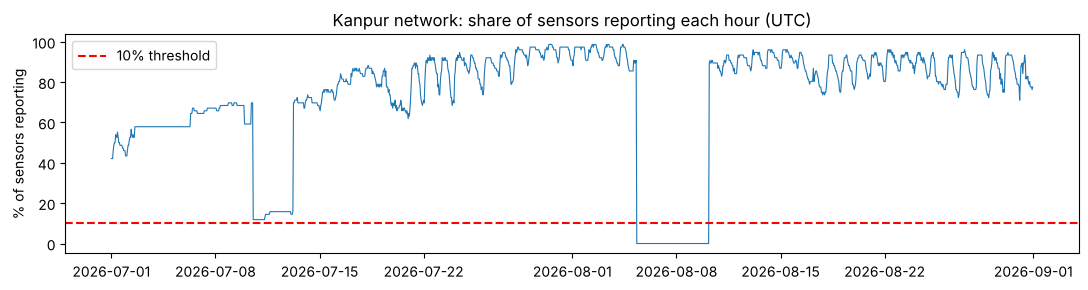

In [8]:
all_hours = pd.date_range(hourly.timestamp_utc.min(), hourly.timestamp_utc.max(), freq="h")
share_reporting = hourly.groupby("timestamp_utc").size().reindex(all_hours, fill_value=0) / len(sensor_ids)
dead_hours = share_reporting[share_reporting < 0.10]
print("hours with < 10% of sensors reporting:", len(dead_hours),
      "from", dead_hours.index.min(), "to", dead_hours.index.max())
print("lowest share in any other hour:", round(share_reporting[share_reporting >= 0.10].min(), 3))

plt.figure(figsize=(11, 3))
plt.plot(share_reporting.index, 100 * share_reporting, lw=0.8)
plt.axhline(10, color="red", ls="--", label="10% threshold")
plt.ylabel("% of sensors reporting")
plt.title("Kanpur network: share of sensors reporting each hour (UTC)")
plt.legend()
plt.tight_layout()
plt.show()

**Findings**
* **Error codes:** 136 hours from 5 sensors, almost all from `1204260025`.
* **Zeros:** two sensors (`1203260082`, `1203260068`) send hundreds of zeros in long blocks.
  Elsewhere zeros are rare one-offs.
* **Stuck:** those zero blocks are also stuck runs. Several sensors also freeze at normal-looking
  values, such as 78 for 126 hours or 14.2 for 74 hours. These are the dangerous ones, because no
  single reading looks wrong.
* **Spikes:** 141 isolated readings far above the city. They are spread over 38 sensors, but more than
  half come from just 4 (`U8APQDBX`, `1204260025`, `1203260075`, `TUOBZVJ0`).
* **Outage:** from 5 Aug 08:00 to 10 Aug 04:00 UTC (117 hours) *no* sensor reports at all.
  Every other hour has at least 12% of sensors reporting, so 10% cleanly separates "network down"
  from "a quiet hour". The outage rule flags no readings, because there are none in those hours.
* **Dropped:** the two zero sensors. Most of their record is flagged.

### Sensors that barely follow the rest of the network
Air in one city is driven by shared weather, so a healthy sensor should go up and down with the
others. For each sensor we correlate its `ok` readings with the median of all *other* sensors in the
same hour.

In [9]:
ok_wide = hourly[hourly.flag == "ok"].pivot(index="timestamp_utc", columns="sensor_id", values="pm25")

follow = {}
for s in ok_wide.columns:
    others_median = ok_wide.drop(columns=s).median(axis=1)
    follow[s] = ok_wide[s].corr(others_median)
follow = pd.Series(follow).sort_values()

print(follow.describe().round(2))
print("\nsensors with correlation below 0.5:\n", follow[follow < 0.5].round(2))

count    74.00
mean      0.74
std       0.10
min       0.39
25%       0.68
50%       0.76
75%       0.81
max       0.87
dtype: float64

sensors with correlation below 0.5:
 AC0BFBE34CC7    0.39
U8APQDBX        0.47
dtype: float64


Most sensors track the network well (median r ≈ 0.76). Two do not: the 15-minute device
`AC0BFBE34CC7` and `U8APQDBX`, which also produced the most spikes. We report them but don't flag
them, because a low correlation could also come from a real local source next to the sensor.

## 4. Write the clean file

In [10]:
clean = hourly[["sensor_id", "timestamp_utc", "latitude", "longitude", "pm25", "flag"]]
clean.to_csv(OUT / "kanpur_hourly_clean.csv", index=False)
print("saved", len(clean), "rows to", OUT / "kanpur_hourly_clean.csv")

saved 82131 rows to outputs/kanpur_hourly_clean.csv


## 5. Calibration check between the two device families

We pair every 10-digit sensor with its nearest 8-character sensor, if it is within 3 km. Using `ok`
readings only, we fit a correction on July and test it on August.

In [11]:
def distance_km(lat1, lon1, lat2, lon2):
    """Flat-earth approximation, accurate enough inside one city."""
    dx = (lon2 - lon1) * 111.32 * np.cos(np.radians(lat1))
    dy = (lat2 - lat1) * 110.57
    return np.sqrt(dx ** 2 + dy ** 2)

location = hourly.groupby("sensor_id")[["latitude", "longitude"]].first()
good = location.index.difference(dropped)
ten_digit = [s for s in good if id_style(s) == "10-digit"]
eight_char = [s for s in good if id_style(s) == "8-char"]

pairs = []
for a in ten_digit:
    d = distance_km(location.latitude[a], location.longitude[a],
                    location.latitude[eight_char], location.longitude[eight_char])
    if d.min() <= 3:
        pairs.append((a, d.idxmin(), round(d.min(), 2)))
pairs = pd.DataFrame(pairs, columns=["ten_digit", "eight_char", "km"])
print(len(pairs), "pairs within 3 km")

# One row per hour where both sensors of a pair have an ok reading
matched = pd.concat([
    pd.DataFrame({"pair": a, "x": ok_wide[a], "y": ok_wide[b]}).dropna()
    for a, b, _ in pairs.itertuples(index=False)
])
july = matched[matched.index.month == 7]
august = matched[matched.index.month == 8]
print("paired hours: July", len(july), "| August", len(august))

21 pairs within 3 km
paired hours: July 7786 | August 11132


In [12]:
# Three candidate corrections, all fitted on July only (x = 10-digit reading, y = 8-char reading)
offset = (july.y - july.x).median()
slope, intercept = np.polyfit(july.x, july.y, 1)
print(f"constant offset: y = x {offset:+.2f}")
print(f"linear fit     : y = {intercept:.2f} + {slope:.3f} * x")

corrections = {
    "no correction": lambda x: x,
    "constant offset": lambda x: x + offset,
    "linear fit": lambda x: intercept + slope * x,
}

def disagreement(df, correct):
    diff = df.y - correct(df.x)
    return {"MAE": diff.abs().mean(), "RMSE": np.sqrt((diff ** 2).mean()), "bias": diff.mean()}

table = {}
for name, correct in corrections.items():
    table[(name, "July (fit)")] = disagreement(july, correct)
    table[(name, "August (test)")] = disagreement(august, correct)
pd.DataFrame(table).T.round(2)

constant offset: y = x -0.13
linear fit     : y = 19.94 + 0.484 * x


MAE   RMSE  bias
no correction   July (fit)     10.79  16.98  1.59
                August (test)  11.73  18.07  1.73
constant offset July (fit)     10.79  16.99  1.72
                August (test)  11.72  18.08  1.85
linear fit      July (fit)     10.46  15.45  0.00
                August (test)  13.11  18.81  0.71

per-pair July offsets range from -10.4 to 9.6 µg/m³
correlation of each pair's offset between July and August: 0.92


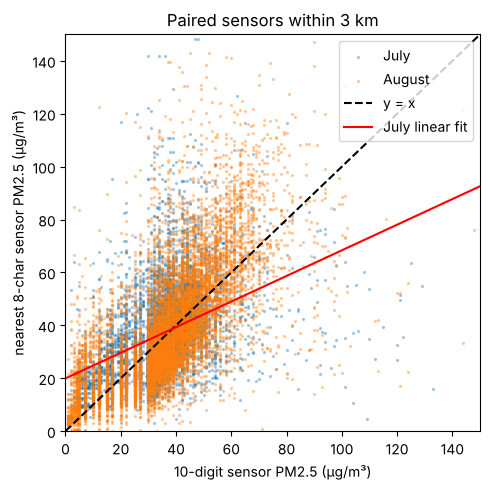

In [13]:
# Is the disagreement the same for every pair, or does each pair have its own offset?
pair_offset = pd.DataFrame({
    "July": (july.y - july.x).groupby(july.pair).median(),
    "August": (august.y - august.x).groupby(august.pair).median(),
})
print(f"per-pair July offsets range from {pair_offset.July.min():.1f} to {pair_offset.July.max():.1f} µg/m³")
print("correlation of each pair's offset between July and August:",
      round(pair_offset.July.corr(pair_offset.August), 2))

plt.figure(figsize=(5, 5))
plt.scatter(july.x, july.y, s=2, alpha=0.3, label="July")
plt.scatter(august.x, august.y, s=2, alpha=0.3, label="August")
line = np.array([0, 150])
plt.plot(line, line, "k--", label="y = x")
plt.plot(line, intercept + slope * line, "r", label="July linear fit")
plt.xlim(0, 150); plt.ylim(0, 150)
plt.xlabel("10-digit sensor PM2.5 (µg/m³)")
plt.ylabel("nearest 8-char sensor PM2.5 (µg/m³)")
plt.title("Paired sensors within 3 km")
plt.legend()
plt.tight_layout()
plt.show()

**Result.** None of the corrections reduces the disagreement (MAE or RMSE) in August.
* The **constant offset** is almost zero, because once bad readings are flagged both families read
  about the same on average. It changes nothing.
* The **linear fit** has a slope well below 1. Noise in the 10-digit readings (whole numbers,
  occasional local peaks) flattens a least-squares line. That is known as regression dilution.
  The line fits July slightly better but makes August *worse*, so it was fitting noise.

**Explanation.** Each pair has its own offset, and that offset is stable from month to month (the
July and August offsets are highly correlated). But the offsets have different signs for different
pairs. So the disagreement isn't a difference between device *families*. It comes from where each
sensor sits (up to 3 km apart, near different local sources) and from individual units. One
correction for a whole family can't fix that. It would need per-sensor calibration, ideally next to
a reference monitor.

## 6. Summary

In [14]:
n_slots = len(sensor_ids) * len(all_hours)          # every sensor, every hour of Jul + Aug
ok_rows = clean[clean.flag == "ok"]
summary = pd.DataFrame({
    "before (raw, hourly)": [len(sensor_ids), len(clean), 1 - len(clean) / n_slots],
    "after (flag == ok)": [ok_rows.sensor_id.nunique(), len(ok_rows), 1 - len(ok_rows) / n_slots],
}, index=["sensors", "sensor-hours with a reading", "share missing"])
summary.round(3)

,"before (raw, hourly)",after (flag == ok)
sensors,76.000,74.000
sensor-hours with a reading,82131.000,79512.000
share missing,0.274,0.297


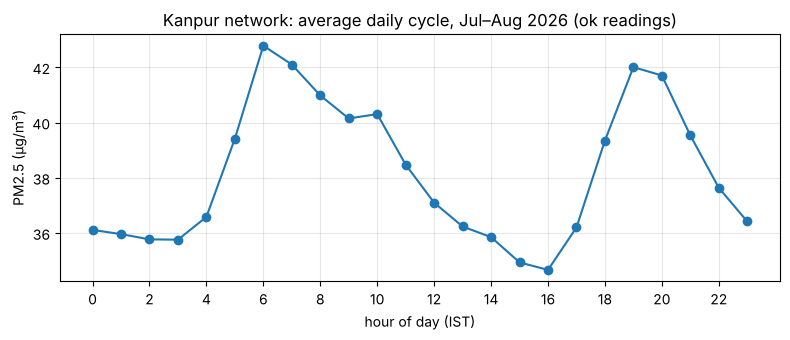

In [15]:
ist = ok_rows.timestamp_utc + pd.Timedelta(hours=5, minutes=30)   # IST = UTC + 5:30
daily_cycle = ok_rows.groupby(ist.dt.hour).pm25.mean()

plt.figure(figsize=(8, 3.5))
plt.plot(daily_cycle.index, daily_cycle.values, marker="o")
plt.xticks(range(0, 24, 2))
plt.xlabel("hour of day (IST)")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Kanpur network: average daily cycle, Jul–Aug 2026 (ok readings)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Even in the monsoon there is a clear daily cycle. PM2.5 is lowest in the afternoon, when sunshine
mixes the air through a deep layer, and highest at night and early morning, when a shallow, stable
layer traps pollution near the ground.